In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import KFold

In [41]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [42]:
for col in df.columns:
    if df[col].dtype == 'object' or isinstance(df[col].dtype, pd.CategoricalDtype):
        df[col] = df[col].fillna('NA')
    else:
        df[col] = df[col].fillna(0.0)

In [43]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [44]:
target_col = 'converted'
y_train = df_train[target_col].values

In [45]:
# Q1
numerical_vars = [
    'lead_score', 
    'number_of_courses_viewed', 
    'interaction_count', 
    'annual_income'
]

auc_results = {}

for col in numerical_vars:
    score = df_train[col].values
    auc = roc_auc_score(y_train, score)
    
    if auc < 0.5:
        auc = roc_auc_score(y_train, -score)
        
    auc_results[col] = auc
    print(f"ROC AUC for {col}: {auc:.4f}")

ROC AUC for lead_score: 0.7882
ROC AUC for number_of_courses_viewed: 0.7230
ROC AUC for interaction_count: 0.7649
ROC AUC for annual_income: 0.6082


In [46]:
best_variable = max(auc_results, key=auc_results.get)
print(f"Variable with the highest AUC: {best_variable} ({auc_results[best_variable]:.4f})")

Variable with the highest AUC: lead_score (0.7882)


In [47]:
# Q2
target_col = 'converted'
features = [col for col in df_train.columns if col != target_col]

train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train[target_col].values
y_val = df_val[target_col].values

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

auc_val = roc_auc_score(y_val, y_pred)
print(f"Validation AUC: {auc_val:.3f}")

Validation AUC: 0.732


Intersection Threshold: 0.63
Precision: 0.733, Recall: 0.727


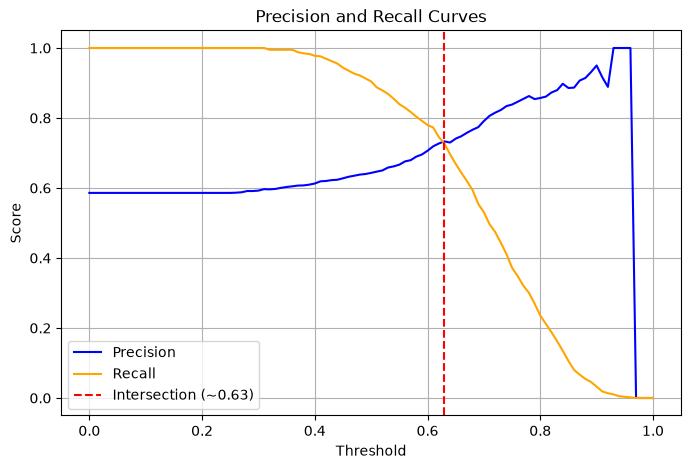

In [48]:
# Q3
thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    y_pred_bin = (y_pred >= t).astype(int)
    
    precision = precision_score(y_val, y_pred_bin, zero_division=0)
    recall = recall_score(y_val, y_pred_bin, zero_division=0)
    
    scores.append((t, precision, recall))
df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

df_scores_filtered = df_scores[(df_scores['precision'] > 0) | (df_scores['recall'] > 0)]

df_scores_filtered['abs_diff'] = np.abs(df_scores_filtered['precision'] - df_scores_filtered['recall'])
intersection_row = df_scores_filtered.loc[df_scores_filtered['abs_diff'].idxmin()]

print(f"Intersection Threshold: {intersection_row['threshold']:.2f}")
print(f"Precision: {intersection_row['precision']:.3f}, Recall: {intersection_row['recall']:.3f}")

# Plotting precision and recall curves
plt.figure(figsize=(8, 5))
plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision', color='blue')
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall', color='orange')
plt.axvline(x=intersection_row['threshold'], color='red', linestyle='--', label=f"Intersection (~{intersection_row['threshold']:.2f})")
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall Curves')
plt.legend()
plt.grid(True)
plt.show()

In [49]:
# Q4
df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / (df_scores['precision'] + df_scores['recall'])
df_scores['f1'] = df_scores['f1'].fillna(0)
max_f1_row = df_scores.loc[df_scores['f1'].idxmax()]

print(f"Threshold with maximum F1: {max_f1_row['threshold']:.2f}")
print(f"Maximum F1 Score: {max_f1_row['f1']:.4f}")

Threshold with maximum F1: 0.41
Maximum F1 Score: 0.7576


In [51]:
# Q5
n_splits = 5
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
scores = []
target_col = 'converted'
features = [col for col in df_full_train.columns if col != target_col]

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    train_dicts = df_train[features].to_dict(orient='records')
    val_dicts = df_val[features].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)
    
    y_train = df_train[target_col].values
    y_val = df_val[target_col].values
    
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    
    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

std_dev = np.std(scores)
print(f"Scores across folds: {[round(s, 4) for s in scores]}")
print(f"Standard Deviation: {std_dev:.3f}")

Scores across folds: [0.7305, 0.7297, 0.7363, 0.7413, 0.721]
Standard Deviation: 0.007


In [52]:
# Q6
C_values = [0.000001, 0.001, 1]
n_splits = 5
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

target_col = 'converted'
features = [col for col in df_full_train.columns if col != target_col]
results = []

for C in C_values:
    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        
        train_dicts = df_train[features].to_dict(orient='records')
        val_dicts = df_val[features].to_dict(orient='records')
        
        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)
        
        y_train = df_train[target_col].values
        y_val = df_val[target_col].values
        
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)
        
        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    
    mean_auc = round(np.mean(scores), 3)
    std_auc = round(np.std(scores), 3)
    results.append((C, mean_auc, std_auc))
    print(f"C={C}: mean AUC = {mean_auc}, std = {std_auc}")

best_c = sorted(results, key=lambda x: (-x[1], x[2], x[0]))[0]
print(f"\nBest C: {best_c[0]}")

C=1e-06: mean AUC = 0.617, std = 0.019
C=0.001: mean AUC = 0.749, std = 0.01
C=1: mean AUC = 0.732, std = 0.007

Best C: 0.001
